# MySteth 2.0 — RQ1: Does SQA filtering change what the model is uncertain about?

**RQ1 (methods document).** *When a recording passes SQA but is borderline-quality, does the downstream model's confidence (from RQ4's UQ module) reflect that residual quality risk, or are SQA and uncertainty estimation blind to each other?*

Methodology, as written:
- train the SQA module (accept / reject / re-record);
- run the full pipeline twice: SQA gate active and SQA disabled;
- for accepted recordings, bucket them by SQA confidence (high vs borderline) and compare the downstream predictive uncertainty (from RQ4) across buckets;
- test: do borderline-quality recordings that passed SQA go with higher predictive uncertainty, or does the model remain falsely confident on them?
- metric: correlation between SQA confidence and downstream predictive entropy; accuracy stratified by bucket.

### The five MySteth 2.0 components and their role here

| # | Component | Role in this notebook |
|---|---|---|
| ① | **SQA** | **The gate being tested:** the final SQA model's out-of-fold `p_good`, its fold threshold and its accept/reject decision, plus the human quality label. |
| ② | SSL | Inside the system model (Domain-SSL start). |
| ③ | Multi-task heads | Both heads; murmur and outcome analysed separately. |
| ④ | **UQ** | **The other side of the question:** RQ4's saved uncertainty of the system model (temperature-scaled ensemble). |
| ⑤ | XAI | Off (RQ5). |

### Fixed, carried over (consistency across the RQ2–RQ6 redo)
- **SQA:** the final SQA model (fusion of five embedding probes + hand-crafted features, trained on human labels; 5-fold out-of-fold scores, so no recording is scored by a model that saw its own label).
- **Downstream:** the RQ3 system model with RQ4's saved scores (out-of-fold, all 3,163 recordings / 942 patients). **Nothing is trained; no GPU, no audio.**
- Thresholds, patient aggregation (murmur = highest recording, outcome = mean), metrics, and **the same 1,000 patient-group bootstrap resamples as RQ3 and RQ4**.
- Unknown-murmur recordings: included wherever only uncertainty is needed; excluded from murmur accuracy; sensitivity check without them.

### Deviations from the methods document (stated in the SQA report)
1. **SQA module:** trained on human quality labels of real CirCor artefacts (crying, breathing, rubbing), not a CNN trained on synthetic noise (Rodrigues et al.). It is binary; **"re-record"** is the outcome for a patient whose recordings are all rejected.
2. **"Run the pipeline twice"** is done post-hoc on the same downstream predictions: *SQA disabled* uses every recording; *SQA active* rebuilds each patient's prediction from passed recordings only. Retraining downstream components on gated data belongs to RQ6's ablation.

### Decided for RQ1 (before writing this notebook)

| Decision | Choice |
|---|---|
| Primary uncertainty | **Binary entropy of the temperature-scaled ensemble** (`ens_temp`) — the doc's "predictive entropy", RQ3's primary. Secondary: RQ4's Chow risk, MC mutual information, ensemble spread. |
| Tasks | murmur and outcome, each analysed fully |
| A. Correlation (doc's metric) | Spearman `p_good` vs entropy, raw and **partial** (controlling murmur Present / Unknown and outcome, as RQ3), over **passed recordings (gate on)** and **all recordings (gate off)**; recording primary, patient secondary; Pearson, Kendall, mutual information alongside |
| B. Buckets | passed recordings ranked by **`p_good − own fold threshold`**: **borderline = lowest third, high = top third** (middle shown). Per bucket: entropy, accuracy, **ECE and overconfidence gap**; borderline − high with paired CIs. Median split as sensitivity check |
| C. Real residual risk | passed recordings humans labelled **Poor** vs passed human-**Good** |
| D. Gate on vs off | patient level: predictions from passed recordings only; none passed = re-record. Against gate off, gate off on the same patients, random recording rejection at the same rate, and **RQ4's confidence gate** at the same coverage; overlap of the two gates; both gates combined vs the confidence gate alone at the same total deferral (10 / 20 / 30 %) |
| Pre-set answer rule (per task, recording level) | **Reflects quality risk** = borderline entropy > high (CI excludes 0) **and** partial ρ(`p_good`, entropy) < 0 among passed recordings. **Falsely confident** = borderline overconfidence gap > high (CI excludes 0). **Blind** = neither the entropy nor the accuracy difference is clear. Same rule for passed human-Poor vs passed human-Good. Gate level: overlap of the two gates vs chance. |

### Kaggle setup
- **No GPU needed.** Attach the final SQA output (`sqa_oof_predictions.csv`) and the **RQ4 output** (`rq4_outputs`).
- Output: `/kaggle/working/rq1_outputs`.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import rankdata, pearsonr, kendalltau
from sklearn.metrics import mutual_info_score
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
NAVY, TEAL, ORANGE, RED, GRAY, PURPLE = "#1F3864", "#1F8A70", "#E67E22", "#C0392B", "#6B7280", "#7D3C98"
SEED = 42

# ---- EDIT THESE PATHS to match your Kaggle inputs ----
SQA_OOF_PATH = Path("/kaggle/input/datasets/tusharrbb/sqa-oof-predictions/sqa_oof_predictions.csv")
RQ4_DIR = Path("/kaggle/input/notebooks/tusharrbb/rq4-redone/rq4_outputs")
OUT = Path("/kaggle/working/rq1_outputs"); OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUT / "figures"; FIG_DIR.mkdir(exist_ok=True)

N_BOOT = 1000
N_RANDOM_POINT = 200          # random recording rejections for the point estimate
N_RANDOM_BOOT = 20            # averaged inside each bootstrap resample
GATE_RATES = (0.10, 0.20, 0.30)
PRIMARY = "ens_temp"
TASKS = ["murmur", "outcome"]
MEASURES = ["entropy", "risk_chow", "mi_mc", "ens_std"]
MEASURE_NAME = {"entropy": "entropy (primary)", "risk_chow": "Chow risk", "mi_mc": "MC mutual information", "ens_std": "ensemble spread"}
POS_NAME = {"murmur": "Present", "outcome": "Abnormal"}
for p_ in [SQA_OOF_PATH, RQ4_DIR / "rq4_recording_scores.csv", RQ4_DIR / "rq4_patient_scores.csv", RQ4_DIR / "rq4_thresholds.csv"]:
    assert p_.exists(), f"not found: {p_} — check the paths"

## 1. Load and join the SQA and downstream outputs

*Components: ① SQA × ④ UQ.*

- One row per recording: SQA `p_good`, its fold threshold, the gate decision (`passed`), the human quality label, and the system model's `ens_temp` probability, decision, correctness and uncertainty measures for each task.
- **Margin** = `p_good − threshold` (how far above or below its own gate a recording sits).
- Checks: all 3,163 recordings join one-to-one; the gate decision equals `p_good ≥ threshold`; aggregating the recording probabilities reproduces RQ4's patient probabilities exactly.

In [2]:
sqa = pd.read_csv(SQA_OOF_PATH)
need = {"wid", "p_good", "threshold", "pred_good", "quality"}
assert need <= set(sqa.columns), f"SQA file is missing {need - set(sqa.columns)}"
R4 = pd.read_csv(RQ4_DIR / "rq4_recording_scores.csv")
P4 = pd.read_csv(RQ4_DIR / "rq4_patient_scores.csv")
TH4 = pd.read_csv(RQ4_DIR / "rq4_thresholds.csv")

rec = R4[(R4.task == "murmur") & (R4.method == PRIMARY)][["wid", "patient_id", "group", "location", "fold", "murmur", "outcome"]]
rec = rec.merge(sqa[["wid", "p_good", "threshold", "pred_good", "quality"]], on="wid", how="inner", validate="one_to_one").reset_index(drop=True)
assert len(rec) == 3163 == len(sqa), (len(rec), len(sqa))
assert ((rec.p_good >= rec.threshold - 1e-12).astype(int) == rec.pred_good).all(), "gate decision is not p_good >= threshold"
rec["passed"] = rec.pred_good.astype(bool)
rec["margin"] = rec.p_good - rec.threshold
rec["human_poor"] = rec.quality.str.lower().eq("poor")
N = len(rec)

TASKDATA = {}
for task in TASKS:
    r = R4[(R4.task == task) & (R4.method == PRIMARY)].set_index("wid").loc[rec.wid]
    d = {k: r[k].values.astype(float) for k in ["y", "p", "threshold", "pred", "correct"] + MEASURES}
    d["labelled"] = d["y"] >= 0
    d["conf"] = np.where(d["pred"] == 1, d["p"], 1 - d["p"])          # the model's probability that its own decision is right
    TASKDATA[task] = d
Y_MUR = TASKDATA["murmur"]["y"]; Y_OUT = TASKDATA["outcome"]["y"]

print(f"recordings {N} | patients {rec.patient_id.nunique()} | groups {rec.group.nunique()}")
print(f"SQA gate passes {rec.passed.sum()} recordings ({rec.passed.mean():.1%}); fold thresholds {sorted(rec.threshold.unique())}")
print("\nHuman quality × gate decision:"); print(pd.crosstab(rec.quality, rec.passed.map({True: "passed", False: "rejected"}), margins=True))
print("\nGate decision by murmur label (row share):"); print(pd.crosstab(rec.murmur, rec.passed.map({True: "passed", False: "rejected"}), normalize="index").round(3))
print("\nMargin above threshold among passed recordings:"); print(rec.margin[rec.passed].describe().round(3))

recordings 3163 | patients 942 | groups 872
SQA gate passes 1864 recordings (58.9%); fold thresholds [np.float64(0.5), np.float64(0.55), np.float64(0.575), np.float64(0.625)]

Human quality × gate decision:
passed   passed  rejected   All
quality                        
Good       1751       403  2154
Poor        113       896  1009
All        1864      1299  3163

Gate decision by murmur label (row share):
passed   passed  rejected
murmur                   
Absent    0.601     0.399
Present   0.666     0.334
Unknown   0.109     0.891

Margin above threshold among passed recordings:
count    1864.000
mean        0.308
std         0.133
min         0.000
25%         0.220
50%         0.343
75%         0.414
max         0.499
Name: margin, dtype: float64


## 2. Helpers: patients, metrics, bootstrap

*Components: evaluation.*

- Patient aggregation from any subset of a patient's recordings: murmur = highest probability, outcome = mean (RQ2–RQ4). A patient with no recording left is **re-record** (deferred).
- Metrics from confusion counts (RQ4's definitions); ECE = positive-class probability, 10 bins.
- **Overconfidence gap** = mean confidence in the decision − accuracy (> 0 = the model claims more than it delivers).
- Bootstrap: the same 1,000 patient-group resamples as RQ3/RQ4 (seed 42, sorted group list).

In [3]:
PAT = P4[(P4.task == "murmur") & (P4.method == PRIMARY)][["patient_id", "group", "fold", "murmur", "outcome"]].reset_index(drop=True)
NP = len(PAT)
rec_pat = rec.patient_id.map(dict(zip(PAT.patient_id, PAT.index))).values
assert not np.isnan(rec_pat.astype(float)).any()
ORDER = np.argsort(rec_pat, kind="stable")
STARTS = np.r_[0, np.flatnonzero(np.diff(rec_pat[ORDER])) + 1]
assert len(STARTS) == NP, "every patient must have at least one recording"

def aggregate(p, keep, task):
    ps, ks = p[ORDER], keep[ORDER]
    cnt = np.add.reduceat(ks.astype(int), STARTS)
    if task == "murmur":
        agg = np.maximum.reduceat(np.where(ks, ps, -np.inf), STARTS)
    else:
        agg = np.add.reduceat(np.where(ks, ps, 0.0), STARTS) / np.maximum(cnt, 1)
    return np.where(cnt > 0, agg, np.nan), cnt > 0

def patient_mean(v, keep):
    vs, ks = v[ORDER], keep[ORDER]
    cnt = np.add.reduceat(ks.astype(int), STARTS)
    return np.where(cnt > 0, np.add.reduceat(np.where(ks, vs, 0.0), STARTS) / np.maximum(cnt, 1), np.nan)

def bin_entropy(p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))

def chow_risk(p, t):
    return np.where(p < t, p / t, (1 - p) / (1 - t))

PTASK = {}
for task in TASKS:
    p4 = P4[(P4.task == task) & (P4.method == PRIMARY)].set_index("patient_id").loc[PAT.patient_id]
    thr = TH4[(TH4.task == task) & (TH4.method == PRIMARY)].set_index("fold").threshold_patient
    t_pat = thr.loc[PAT.fold].values
    assert np.allclose(t_pat, p4.threshold.values), f"{task}: patient thresholds differ from RQ4"
    p_off, _ = aggregate(TASKDATA[task]["p"], np.ones(N, bool), task)
    assert np.allclose(p_off, p4.p.values, atol=1e-6), f"{task}: aggregation does not reproduce RQ4's patient probabilities"
    p_on, cov_on = aggregate(TASKDATA[task]["p"], rec.passed.values, task)
    PTASK[task] = {"y": p4.y.values.astype(float), "t": t_pat, "p_off": p_off, "p_on": p_on, "covered_on": cov_on}
COVERED = PTASK["murmur"]["covered_on"]
print(f"Patients with at least one passed recording: {COVERED.sum()} of {NP} ({COVERED.mean():.1%}); re-record: {(~COVERED).sum()}")
print("RQ4's patient probabilities and thresholds reproduced exactly")

def auc_fast(y, s):
    n1 = int(np.sum(y == 1)); n0 = len(y) - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    r = rankdata(s)
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def ece_binary(y, p, n_bins=10):
    if len(p) == 0:
        return np.nan
    b = np.minimum((p * n_bins).astype(int), n_bins - 1)
    return float(np.abs(np.bincount(b, weights=y, minlength=n_bins) - np.bincount(b, weights=p, minlength=n_bins)).sum() / len(p))

def c_outcome(y, yhat):
    n = len(y); r = yhat.mean()
    tp = ((yhat == 1) & (y == 1)).sum(); fn = ((yhat == 0) & (y == 1)).sum()
    return (10 * n + (25 + 397 * r - 1718 * r ** 2 + 11296 * r ** 4) * n + 10000 * tp + 50000 * fn) / n

def clf_metrics(y, p, yhat, task):
    tp = int(np.sum((yhat == 1) & (y == 1))); tn = int(np.sum((yhat == 0) & (y == 0)))
    fp = int(np.sum((yhat == 1) & (y == 0))); fn = int(np.sum((yhat == 0) & (y == 1)))
    n, P, Nn = len(y), tp + fn, tn + fp
    f1s = []
    if P + fp > 0:
        f1s.append(2 * tp / (2 * tp + fp + fn))
    if Nn + fn > 0:
        f1s.append(2 * tn / (2 * tn + fp + fn))
    conf = np.where(yhat == 1, p, 1 - p)
    out = {"n": n, "F1 (macro)": np.mean(f1s) if f1s else np.nan, "Accuracy": (tp + tn) / n if n else np.nan,
           "Weighted accuracy": (5 * tp + tn) / (5 * P + Nn) if n else np.nan, "AUC": auc_fast(y, p),
           "Sensitivity": tp / P if P else np.nan, "Specificity": tn / Nn if Nn else np.nan, "ECE": ece_binary(y, p),
           "Overconfidence gap": conf.mean() - (tp + tn) / n if n else np.nan, "Mean entropy": bin_entropy(p).mean() if n else np.nan}
    if task == "outcome":
        out["Cost (c_outcome)"] = c_outcome(y, yhat) if n else np.nan
    return out

rng_boot = np.random.default_rng(SEED)
G_ALL = np.array(sorted(rec.group.unique()))
BOOT_GROUPS = [rng_boot.choice(G_ALL, size=len(G_ALL), replace=True) for _ in range(N_BOOT)]
def boot_index_sets(unit_groups):
    pos = pd.Series(np.arange(len(unit_groups))).groupby(unit_groups).apply(np.array).to_dict()
    return [np.concatenate([pos[g] for g in bg if g in pos]) for bg in BOOT_GROUPS]
BI_REC = boot_index_sets(rec.group.values)
BI_PAT = boot_index_sets(PAT.group.values)

fmt_ci = lambda v, lo, hi, d=3: f"{v:.{d}f} [{lo:.{d}f}, {hi:.{d}f}]"
fmt_dci = lambda v, lo, hi, d=3: f"{v:+.{d}f} [{lo:+.{d}f}, {hi:+.{d}f}]"
print(f"SQA sanity check: AUC of p_good for the human Good label = {auc_fast((~rec.human_poor).astype(int).values, rec.p_good.values):.3f}")

Patients with at least one passed recording: 734 of 942 (77.9%); re-record: 208
RQ4's patient probabilities and thresholds reproduced exactly
SQA sanity check: AUC of p_good for the human Good label = 0.929


## 3. Analysis A — correlation between SQA confidence and downstream uncertainty (the doc's metric)

*Components: ① × ④.*

Higher `p_good` = better quality according to SQA; higher entropy = more uncertain. If the downstream model "sees" quality, the correlation is **negative**.

- **Gate on:** passed recordings only. **Gate off:** all recordings.
- **Partial ρ:** rank both variables, regress each on murmur Present / Unknown indicators and the outcome label, correlate the residuals (RQ3's method), so the link cannot be just "Unknown murmurs are both noisy and hard".
- Patient level: a patient's `p_good` is the mean over the recordings used; their uncertainty is computed from the aggregated probability (gate on: passed recordings only). Patient level uses entropy and Chow risk (MC mutual information and ensemble spread need per-pass data that is not aggregated by subset).

,level,task,gate,subset,n,ρ (95% CI),partial ρ (95% CI),pearson,kendall,mutual_info
0,recording,murmur,gate on (passed),all,1864,"-0.115 [-0.170, -0.056]","-0.112 [-0.166, -0.052]",-0.095,-0.077,0.029
4,recording,murmur,gate on (passed),without Unknown murmur,1847,"-0.113 [-0.168, -0.053]","-0.113 [-0.168, -0.053]",-0.092,-0.076,0.028
5,recording,murmur,gate off (all),all,3163,"-0.203 [-0.249, -0.155]","-0.191 [-0.236, -0.143]",-0.159,-0.136,0.041
9,recording,murmur,gate off (all),without Unknown murmur,3007,"-0.189 [-0.235, -0.137]","-0.195 [-0.241, -0.146]",-0.144,-0.126,0.041
10,patient,murmur,gate on (passed),all,734,"-0.057 [-0.130, +0.020]","-0.045 [-0.124, +0.032]",-0.048,-0.038,0.052
12,patient,murmur,gate off (all),all,942,"-0.199 [-0.259, -0.142]","-0.157 [-0.220, -0.096]",-0.193,-0.134,0.069
14,recording,outcome,gate on (passed),all,1864,"-0.047 [-0.096, +0.006]","-0.055 [-0.105, -0.006]",-0.038,-0.031,0.030
18,recording,outcome,gate on (passed),without Unknown murmur,1847,"-0.048 [-0.098, +0.006]","-0.057 [-0.107, -0.007]",-0.038,-0.032,0.031
19,recording,outcome,gate off (all),all,3163,"-0.128 [-0.173, -0.083]","-0.109 [-0.156, -0.065]",-0.116,-0.085,0.021
23,recording,outcome,gate off (all),without Unknown murmur,3007,"-0.119 [-0.165, -0.073]","-0.109 [-0.158, -0.063]",-0.107,-0.079,0.023



Secondary measures (all recordings / patients in the subset):


measure                                             ens_std                  entropy                    mi_mc                risk_chow
level     task    gate                                                                                                                
patient   murmur  gate off (all)                        NaN  -0.157 [-0.220, -0.096]                      NaN  -0.159 [-0.222, -0.096]
                  gate on (passed)                      NaN  -0.045 [-0.124, +0.032]                      NaN  -0.044 [-0.122, +0.032]
          outcome gate off (all)                        NaN  -0.093 [-0.154, -0.026]                      NaN  +0.073 [+0.011, +0.141]
                  gate on (passed)                      NaN  -0.022 [-0.094, +0.051]                      NaN  +0.038 [-0.039, +0.120]
recording murmur  gate off (all)    -0.035 [-0.079, +0.010]  -0.191 [-0.236, -0.143]  -0.053 [-0.101, -0.010]  -0.216 [-0.260, -0.172]
                  gate on (passed)  -0.024 [-0.079, +0.033]  -0.112 [-0.166, -0.052]  -0.079 [-0.136, -0.027]  -0.128 [-0.179, -0.073]
          outcome gate off (all)    -0.026 [-0.063, +0.015]  -0.109 [-0.156, -0.065]  +0.156 [+0.113, +0.195]  +0.003 [-0.037, +0.047]
                  gate on (passed)  +0.016 [-0.033, +0.070]  -0.055 [-0.105, -0.006]  +0.060 [+0.008, +0.112]  -0.007 [-0.056, +0.049]

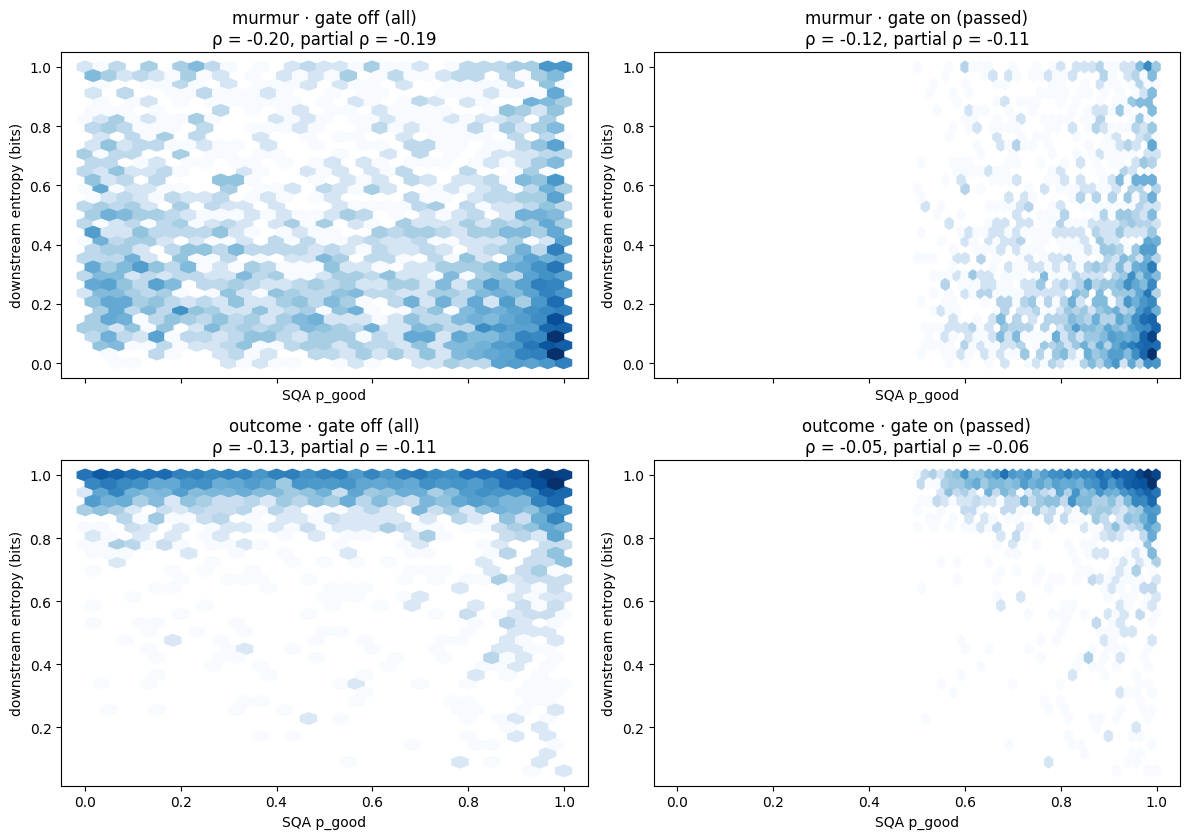

In [4]:
def spearman(a, b):
    return np.corrcoef(rankdata(a), rankdata(b))[0, 1]

def partial_spearman(a, b, C):
    ra, rb = rankdata(a), rankdata(b)
    res_a = ra - C @ np.linalg.lstsq(C, ra, rcond=None)[0]
    res_b = rb - C @ np.linalg.lstsq(C, rb, rcond=None)[0]
    return np.corrcoef(res_a, res_b)[0, 1]

def mutual_info(a, b, bins=10):
    qa = np.digitize(a, np.quantile(a, np.linspace(0, 1, bins + 1)[1:-1]))
    qb = np.digitize(b, np.quantile(b, np.linspace(0, 1, bins + 1)[1:-1]))
    return mutual_info_score(qa, qb)

def covars(ym, yo):
    return np.column_stack([np.ones(len(ym)), (ym == 1).astype(float), (ym == -1).astype(float), yo])

def corr_row(x, u, ym, yo, groups, label):
    C = covars(ym, yo)
    bis = boot_index_sets(groups)
    bs_r = np.array([spearman(x[b], u[b]) for b in bis])
    bs_p = np.array([partial_spearman(x[b], u[b], covars(ym[b], yo[b])) for b in bis])
    r, pr = spearman(x, u), partial_spearman(x, u, C)
    return {**label, "n": len(x), "spearman": r, "spearman_lo": np.nanpercentile(bs_r, 2.5), "spearman_hi": np.nanpercentile(bs_r, 97.5),
            "partial": pr, "partial_lo": np.nanpercentile(bs_p, 2.5), "partial_hi": np.nanpercentile(bs_p, 97.5),
            "pearson": pearsonr(x, u)[0], "kendall": kendalltau(x, u)[0], "mutual_info": mutual_info(x, u)}

corr_rows = []
for task in TASKS:
    d = TASKDATA[task]
    for gate, mask in [("gate on (passed)", rec.passed.values), ("gate off (all)", np.ones(N, bool))]:
        for sub, extra in [("all", np.ones(N, bool)), ("without Unknown murmur", Y_MUR >= 0)]:
            m = mask & extra
            for meas in MEASURES:
                if sub != "all" and meas != "entropy":
                    continue
                corr_rows.append(corr_row(rec.p_good.values[m], d[meas][m], Y_MUR[m], Y_OUT[m], rec.group.values[m],
                                          {"level": "recording", "task": task, "gate": gate, "subset": sub, "measure": meas}))
    # patient level
    pt = PTASK[task]
    ymP, yoP = PTASK["murmur"]["y"], PTASK["outcome"]["y"]
    for gate, keep in [("gate on (passed)", rec.passed.values), ("gate off (all)", np.ones(N, bool))]:
        q = patient_mean(rec.p_good.values, keep)
        p = pt["p_on"] if gate.startswith("gate on") else pt["p_off"]
        ok = ~np.isnan(p)
        for meas, u in [("entropy", bin_entropy(p)), ("risk_chow", chow_risk(p, pt["t"]))]:
            corr_rows.append(corr_row(q[ok], u[ok], ymP[ok], yoP[ok], PAT.group.values[ok],
                                      {"level": "patient", "task": task, "gate": gate, "subset": "all", "measure": meas}))
corr = pd.DataFrame(corr_rows)
corr["ρ (95% CI)"] = [fmt_dci(r.spearman, r.spearman_lo, r.spearman_hi) for r in corr.itertuples()]
corr["partial ρ (95% CI)"] = [fmt_dci(r.partial, r.partial_lo, r.partial_hi) for r in corr.itertuples()]
display(corr[corr.measure == "entropy"][["level", "task", "gate", "subset", "n", "ρ (95% CI)", "partial ρ (95% CI)", "pearson", "kendall", "mutual_info"]].round(3))
print("\nSecondary measures (all recordings / patients in the subset):")
display(corr[(corr.subset == "all")].pivot_table(index=["level", "task", "gate"], columns="measure", values="partial ρ (95% CI)", aggfunc="first"))

fig, axes = plt.subplots(2, 2, figsize=(12, 8.5), sharex=True)
for i, task in enumerate(TASKS):
    for j, (gate, mask) in enumerate([("gate off (all)", np.ones(N, bool)), ("gate on (passed)", rec.passed.values)]):
        ax = axes[i, j]
        ax.hexbin(rec.p_good.values[mask], TASKDATA[task]["entropy"][mask], gridsize=30, cmap="Blues", mincnt=1, bins="log")
        r = corr[(corr.level == "recording") & (corr.task == task) & (corr.gate == gate) & (corr.subset == "all") & (corr.measure == "entropy")].iloc[0]
        ax.set(title=f"{task} · {gate}\nρ = {r.spearman:+.2f}, partial ρ = {r.partial:+.2f}", xlabel="SQA p_good", ylabel="downstream entropy (bits)")
plt.tight_layout(); plt.savefig(FIG_DIR / "rq1_correlation.png", dpi=200); plt.show()

## 4. Analyses B and C — borderline vs high, and the real residual risk

*Components: ① × ④.*

**B.** Passed recordings are ranked by their margin above their own threshold: **borderline** = lowest third (only just passed), **middle**, **high** = top third. A median split (lower vs upper half) is the sensitivity check.

**C.** Among passed recordings: those humans labelled **Poor** (the SQA's misses) vs those labelled **Good**.

Per group: mean entropy (and the secondary measures), accuracy, ECE, mean confidence and **overconfidence gap**. Entropy uses every recording in the group; accuracy, ECE and the gap use labelled recordings (Unknown murmur excluded for murmur). Differences (first group − second) have paired bootstrap CIs; group membership is fixed and patient groups are resampled.

margin cut-points among passed: thirds 0.274 / 0.392, median 0.343
quality     Good  Poor   All
bucket                      
borderline   529    93   622
high         617     5   622
middle       605    15   620
rejected     403   896  1299
All         2154  1009  3163

===== MURMUR — group values =====


,comparison,group,n,n labelled,mean entropy,accuracy,ECE,mean confidence,overconfidence gap,mean risk_chow,mean mi_mc,mean ens_std
0,B: borderline − high (thirds),borderline,622,610,0.365,0.861,0.035,0.853,-0.007,0.342,0.003,0.032
1,B: borderline − high (thirds),high,622,621,0.317,0.890,0.021,0.880,-0.010,0.275,0.003,0.037
2,B (sensitivity): lower − upper half,lower half,932,917,0.348,0.875,0.030,0.864,-0.011,0.324,0.003,0.032
3,B (sensitivity): lower − upper half,upper half,932,930,0.313,0.887,0.026,0.882,-0.005,0.271,0.003,0.035
4,"B (sensitivity): borderline − high, without Un...",borderline,610,610,0.363,0.861,0.035,0.853,-0.007,0.340,0.003,0.032
5,"B (sensitivity): borderline − high, without Un...",high,621,621,0.316,0.890,0.021,0.880,-0.010,0.275,0.003,0.037
6,C: passed human-Poor − passed human-Good,"passed, human Poor",113,104,0.384,0.837,0.071,0.849,0.012,0.353,0.003,0.032
7,C: passed human-Poor − passed human-Good,"passed, human Good",1751,1743,0.327,0.884,0.023,0.875,-0.009,0.294,0.003,0.033
8,D-rec: rejected − passed,rejected,1299,1160,0.406,0.853,0.041,0.845,-0.008,0.396,0.003,0.031
9,D-rec: rejected − passed,passed,1864,1847,0.331,0.881,0.024,0.873,-0.008,0.298,0.003,0.033


===== MURMUR — differences (first − second; * = 95% CI excludes 0) =====


comparison,"B (sensitivity): borderline − high, without Unknown",B (sensitivity): lower − upper half,B: borderline − high (thirds),C: passed human-Poor − passed human-Good,D-rec: rejected − passed
quantity,,,,,
mean entropy,"+0.0464 [+0.0073, +0.0859] *","+0.0346 [+0.0040, +0.0644] *","+0.0480 [+0.0090, +0.0867] *","+0.0569 [+0.0013, +0.1151] *","+0.0754 [+0.0510, +0.1004] *"
accuracy,"-0.030 [-0.070, +0.013]","-0.013 [-0.044, +0.021]","-0.030 [-0.070, +0.013]","-0.047 [-0.124, +0.024]","-0.028 [-0.057, -0.002] *"
ECE,"+0.014 [-0.017, +0.032]","+0.004 [-0.022, +0.024]","+0.014 [-0.017, +0.032]","+0.048 [+0.014, +0.111] *","+0.017 [-0.003, +0.037]"
mean confidence,"-0.0270 [-0.0533, +0.0019]","-0.0185 [-0.0394, +0.0033]","-0.0270 [-0.0533, +0.0019]","-0.0261 [-0.0715, +0.0188]","-0.0283 [-0.0465, -0.0097] *"
overconfidence gap,"+0.003 [-0.029, +0.031]","-0.006 [-0.034, +0.018]","+0.003 [-0.029, +0.031]","+0.021 [-0.036, +0.080]","-0.000 [-0.021, +0.022]"
mean risk_chow,"+0.0654 [+0.0267, +0.1006] *","+0.0524 [+0.0241, +0.0798] *","+0.0668 [+0.0283, +0.1027] *","+0.0589 [+0.0029, +0.1118] *","+0.0984 [+0.0760, +0.1218] *"
mean mi_mc,"-0.0004 [-0.0010, +0.0002]","-0.0004 [-0.0009, +0.0001]","-0.0004 [-0.0010, +0.0002]","-0.0001 [-0.0007, +0.0005]","-0.0002 [-0.0005, +0.0000]"
mean ens_std,"-0.0047 [-0.0107, +0.0009]","-0.0031 [-0.0079, +0.0012]","-0.0047 [-0.0107, +0.0009]","-0.0010 [-0.0079, +0.0063]","-0.0025 [-0.0059, +0.0010]"



===== OUTCOME — group values =====


,comparison,group,n,n labelled,mean entropy,accuracy,ECE,mean confidence,overconfidence gap,mean risk_chow,mean mi_mc,mean ens_std
0,B: borderline − high (thirds),borderline,622,622,0.912,0.555,0.058,0.582,0.027,0.782,0.005,0.045
1,B: borderline − high (thirds),high,622,622,0.911,0.563,0.069,0.584,0.022,0.789,0.006,0.046
2,B (sensitivity): lower − upper half,lower half,932,932,0.906,0.561,0.061,0.585,0.024,0.778,0.005,0.045
3,B (sensitivity): lower − upper half,upper half,932,932,0.901,0.578,0.077,0.592,0.013,0.775,0.006,0.046
4,"B (sensitivity): borderline − high, without Un...",borderline,610,610,0.911,0.549,0.062,0.582,0.032,0.782,0.005,0.044
5,"B (sensitivity): borderline − high, without Un...",high,621,621,0.911,0.562,0.070,0.584,0.022,0.789,0.006,0.046
6,C: passed human-Poor − passed human-Good,"passed, human Poor",113,113,0.914,0.496,0.143,0.588,0.093,0.790,0.005,0.047
7,C: passed human-Poor − passed human-Good,"passed, human Good",1751,1751,0.903,0.575,0.054,0.588,0.014,0.775,0.006,0.045
8,D-rec: rejected − passed,rejected,1299,1299,0.934,0.527,0.049,0.559,0.032,0.800,0.004,0.047
9,D-rec: rejected − passed,passed,1864,1864,0.903,0.570,0.054,0.588,0.019,0.776,0.006,0.046


===== OUTCOME — differences (first − second; * = 95% CI excludes 0) =====


comparison,"B (sensitivity): borderline − high, without Unknown",B (sensitivity): lower − upper half,B: borderline − high (thirds),C: passed human-Poor − passed human-Good,D-rec: rejected − passed
quantity,,,,,
mean entropy,"+0.0001 [-0.0207, +0.0198]","+0.0050 [-0.0121, +0.0205]","+0.0005 [-0.0200, +0.0198]","+0.0116 [-0.0181, +0.0391]","+0.0304 [+0.0175, +0.0433] *"
accuracy,"-0.013 [-0.071, +0.053]","-0.017 [-0.065, +0.036]","-0.008 [-0.067, +0.056]","-0.079 [-0.173, +0.019]","-0.042 [-0.086, -0.000] *"
ECE,"-0.008 [-0.051, +0.050]","-0.017 [-0.057, +0.032]","-0.012 [-0.054, +0.046]","+0.090 [+0.021, +0.175] *","-0.005 [-0.042, +0.029]"
mean confidence,"-0.0029 [-0.0227, +0.0166]","-0.0066 [-0.0216, +0.0095]","-0.0026 [-0.0223, +0.0167]","+0.0002 [-0.0277, +0.0258]","-0.0293 [-0.0408, -0.0173] *"
overconfidence gap,"+0.010 [-0.047, +0.063]","+0.011 [-0.037, +0.057]","+0.005 [-0.052, +0.058]","+0.079 [-0.010, +0.166]","+0.013 [-0.028, +0.055]"
mean risk_chow,"-0.0074 [-0.0416, +0.0262]","+0.0024 [-0.0243, +0.0276]","-0.0071 [-0.0412, +0.0266]","+0.0149 [-0.0329, +0.0575]","+0.0232 [+0.0037, +0.0438] *"
mean mi_mc,"-0.0010 [-0.0019, -0.0002] *","-0.0009 [-0.0016, -0.0003] *","-0.0010 [-0.0019, -0.0002] *","-0.0010 [-0.0017, -0.0003] *","-0.0012 [-0.0017, -0.0009] *"
mean ens_std,"-0.0018 [-0.0054, +0.0013]","-0.0009 [-0.0038, +0.0017]","-0.0016 [-0.0052, +0.0014]","+0.0013 [-0.0038, +0.0067]","+0.0012 [-0.0009, +0.0031]"


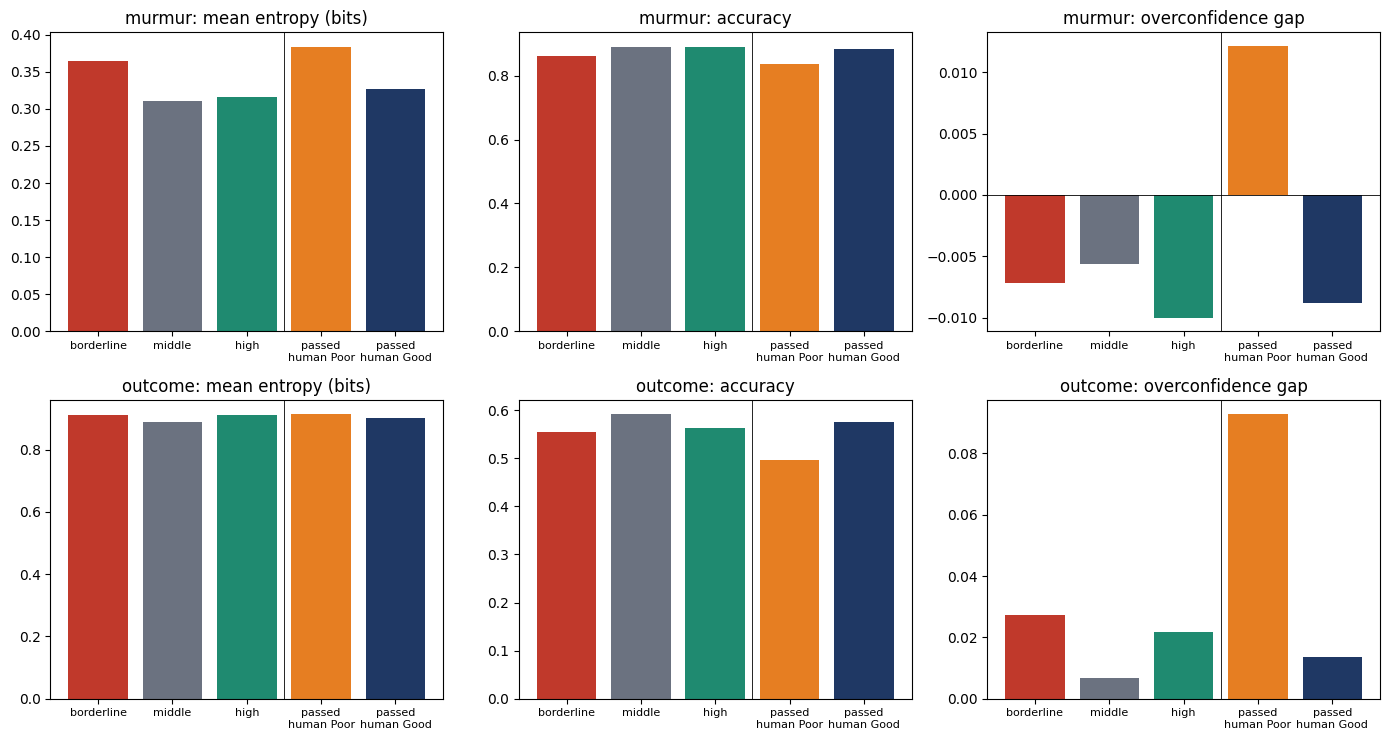

In [5]:
pas = np.where(rec.passed.values)[0]
q1, q2 = np.quantile(rec.margin.values[pas], [1 / 3, 2 / 3])
med = np.median(rec.margin.values[pas])
bucket = np.full(N, "rejected", dtype=object)
bucket[pas] = np.where(rec.margin.values[pas] <= q1, "borderline", np.where(rec.margin.values[pas] >= q2, "high", "middle"))
half = np.full(N, "rejected", dtype=object)
half[pas] = np.where(rec.margin.values[pas] <= med, "lower half", "upper half")
rec["bucket"], rec["half"] = bucket, half
print(f"margin cut-points among passed: thirds {q1:.3f} / {q2:.3f}, median {med:.3f}")
print(pd.crosstab(rec.bucket, rec.quality, margins=True))

def group_stats(idx, task):
    d = TASKDATA[task]
    out = {"n": len(idx)}
    for meas in MEASURES:
        out[f"mean {meas}"] = d[meas][idx].mean() if len(idx) else np.nan
    lab = idx[d["labelled"][idx]]
    out["n labelled"] = len(lab)
    if len(lab):
        y, p, c, correct = d["y"][lab], d["p"][lab], d["conf"][lab], d["correct"][lab]
        out.update({"accuracy": correct.mean(), "ECE": ece_binary(y, p), "mean confidence": c.mean(), "overconfidence gap": c.mean() - correct.mean()})
    else:
        out.update({"accuracy": np.nan, "ECE": np.nan, "mean confidence": np.nan, "overconfidence gap": np.nan})
    return out

COMPARISONS = {   # name -> (mask A, mask B, label A, label B)
    "B: borderline − high (thirds)": (bucket == "borderline", bucket == "high", "borderline", "high"),
    "B (sensitivity): lower − upper half": (half == "lower half", half == "upper half", "lower half", "upper half"),
    "B (sensitivity): borderline − high, without Unknown": ((bucket == "borderline") & (Y_MUR >= 0), (bucket == "high") & (Y_MUR >= 0), "borderline", "high"),
    "C: passed human-Poor − passed human-Good": (rec.passed.values & rec.human_poor.values, rec.passed.values & ~rec.human_poor.values, "passed, human Poor", "passed, human Good"),
    "D-rec: rejected − passed": (~rec.passed.values, rec.passed.values, "rejected", "passed"),
}
grp_rows, diff_rows = [], []
for task in TASKS:
    for name, (ma, mb, la, lb) in COMPARISONS.items():
        sa, sb = group_stats(np.where(ma)[0], task), group_stats(np.where(mb)[0], task)
        grp_rows += [{"task": task, "comparison": name, "group": la, **sa}, {"task": task, "comparison": name, "group": lb, **sb}]
        boots = []
        for b in BI_REC:
            ba, bb = b[ma[b]], b[mb[b]]
            boots.append((group_stats(ba, task), group_stats(bb, task)))
        for k in sa:
            if k.startswith("n"):
                continue
            dd = np.array([x[k] - y_[k] for x, y_ in boots], dtype=float)
            lo, hi = np.nanpercentile(dd, [2.5, 97.5])
            diff_rows.append({"task": task, "comparison": name, "quantity": k, "difference": sa[k] - sb[k], "ci_low": lo, "ci_high": hi,
                              "clear": (lo > 0) or (hi < 0)})
    mid = group_stats(np.where(bucket == "middle")[0], task)
    grp_rows.append({"task": task, "comparison": "B: borderline − high (thirds)", "group": "middle (not tested)", **mid})
groups_df = pd.DataFrame(grp_rows)
diffs = pd.DataFrame(diff_rows)
diffs["difference (95% CI)"] = [fmt_dci(r.difference, r.ci_low, r.ci_high, 4 if "mean" in r.quantity else 3) + (" *" if r.clear else "") for r in diffs.itertuples()]
SHOW_Q = ["mean entropy", "accuracy", "ECE", "mean confidence", "overconfidence gap", "mean risk_chow", "mean mi_mc", "mean ens_std"]
for task in TASKS:
    print(f"\n===== {task.upper()} — group values =====")
    g = groups_df[groups_df.task == task]
    display(g[["comparison", "group", "n", "n labelled"] + SHOW_Q].round(3).reset_index(drop=True))
    print(f"===== {task.upper()} — differences (first − second; * = 95% CI excludes 0) =====")
    s = diffs[diffs.task == task]
    display(s.pivot_table(index="quantity", columns="comparison", values="difference (95% CI)", aggfunc="first").reindex(SHOW_Q))

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for i, task in enumerate(TASKS):
    g = groups_df[(groups_df.task == task) & (groups_df.comparison == "B: borderline − high (thirds)")].set_index("group")
    c = groups_df[(groups_df.task == task) & (groups_df.comparison == "C: passed human-Poor − passed human-Good")].set_index("group")
    names = ["borderline", "middle (not tested)", "high", "passed, human Poor", "passed, human Good"]
    vals = pd.concat([g, c])
    cols = [RED, GRAY, TEAL, ORANGE, NAVY]
    for j, (q, lab) in enumerate([("mean entropy", "mean entropy (bits)"), ("accuracy", "accuracy"), ("overconfidence gap", "overconfidence gap")]):
        ax = axes[i, j]
        ax.bar(range(5), [vals.loc[nm, q] for nm in names], color=cols)
        ax.set_xticks(range(5)); ax.set_xticklabels(["borderline", "middle", "high", "passed\nhuman Poor", "passed\nhuman Good"], fontsize=8)
        ax.axvline(2.5, color="black", lw=0.6)
        if q == "overconfidence gap":
            ax.axhline(0, color="black", lw=0.6)
        ax.set(title=f"{task}: {lab}")
plt.tight_layout(); plt.savefig(FIG_DIR / "rq1_buckets.png", dpi=200); plt.show()

## 5. Analysis D — gate on vs off at patient level, and the SQA gate vs the confidence gate

*Components: ① SQA gate × ④ confidence gate, as in the RQ6 pipeline.*

| scenario | patients scored | probability |
|---|---|---|
| gate off | all | all recordings |
| **gate on** | patients with ≥ 1 passed recording | passed recordings only |
| gate off, same patients | the gate-on patients | all recordings — separates *dropping poor recordings within a patient* from *excluding patients* |
| random recording rejection | patients with ≥ 1 kept recording | reject the same share of recordings at random (mean of 200 draws; 20 per bootstrap resample) |
| confidence gate (same coverage) | all minus the same share of patients, highest Chow risk (RQ4 primary) first; entropy as check | all recordings |
| SQA + confidence gate | SQA gate, then the confidence gate defers more patients until the total reaches 10 / 20 / 30 % | passed recordings |
| confidence gate alone at the same total | — | all recordings |

**Blind to each other?** Overlap of the patients each gate defers (same number), and, per recording, the overlap of SQA-rejected recordings with the same number of highest-entropy recordings, both as observed / expected under independence, plus the AUROC of downstream entropy for detecting SQA rejection and human-Poor quality.

In [6]:
def deferral_mask(risk, k, tb):
    m = np.zeros(len(risk), bool)
    if k > 0:
        m[np.lexsort((tb, -risk))[:k]] = True
    return m

rng_tb = np.random.default_rng(SEED)
TB_P = rng_tb.random(NP); TB_R = rng_tb.random(N)
rec_reject_rate = 1 - rec.passed.mean()
rng_rand = np.random.default_rng(SEED + 3)
RAND_KEEP = [rng_rand.random(N) >= rec_reject_rate for _ in range(N_RANDOM_POINT)]

gate_rows, gdiff_rows, overlap_rows = [], [], []
for task in TASKS:
    pt = PTASK[task]
    lab = np.where(pt["y"] >= 0)[0]
    y, t = pt["y"], pt["t"]
    risk_off = {"chow": chow_risk(pt["p_off"], t), "entropy": bin_entropy(pt["p_off"])}
    rand_aggs = [aggregate(TASKDATA[task]["p"], k_, task) for k_ in RAND_KEEP]

    def scen(ix):
        # all scenario metrics on patient index array ix (labelled patients, possibly with repeats)
        n = len(ix)
        out = {}
        cov = pt["covered_on"][ix]
        out["gate off"] = clf_metrics(y[ix], pt["p_off"][ix], (pt["p_off"][ix] >= t[ix]).astype(int), task)
        ion = ix[cov]
        out["gate on"] = clf_metrics(y[ion], pt["p_on"][ion], (pt["p_on"][ion] >= t[ion]).astype(int), task)
        out["gate off, same patients"] = clf_metrics(y[ion], pt["p_off"][ion], (pt["p_off"][ion] >= t[ion]).astype(int), task)
        k_sqa = int((~cov).sum())
        for sc in ["chow", "entropy"]:
            dm = deferral_mask(risk_off[sc][ix], k_sqa, TB_P[ix])
            kept = ix[~dm]
            out[f"confidence gate ({sc}), same coverage"] = clf_metrics(y[kept], pt["p_off"][kept], (pt["p_off"][kept] >= t[kept]).astype(int), task)
        for rate in GATE_RATES:
            k_tot = int(round(rate * n))
            # SQA gate first, then the confidence gate (Chow on gate-on probabilities) up to the total
            extra = max(k_tot - k_sqa, 0)
            r_on = chow_risk(np.nan_to_num(pt["p_on"][ion], nan=0.5), t[ion])
            dm = deferral_mask(r_on, extra, TB_P[ion]); kept = ion[~dm]
            out[f"SQA + confidence gate, total {rate:.0%}"] = clf_metrics(y[kept], pt["p_on"][kept], (pt["p_on"][kept] >= t[kept]).astype(int), task)
            dm = deferral_mask(risk_off["chow"][ix], k_tot, TB_P[ix]); kept = ix[~dm]
            out[f"confidence gate alone, total {rate:.0%}"] = clf_metrics(y[kept], pt["p_off"][kept], (pt["p_off"][kept] >= t[kept]).astype(int), task)
        for key in out:
            out[key]["coverage"] = out[key]["n"] / n
        return out

    def rand_scen(ix, draws):
        ms = []
        for j in draws:
            pr, cv = rand_aggs[j]
            k_ = ix[cv[ix]]
            m_ = clf_metrics(y[k_], pr[k_], (pr[k_] >= t[k_]).astype(int), task); m_["coverage"] = len(k_) / len(ix)
            ms.append(m_)
        return {k: np.nanmean([m_[k] for m_ in ms]) for k in ms[0]}

    point = scen(lab); point["random recording rejection"] = rand_scen(lab, range(N_RANDOM_POINT))
    boots = []
    for bi, b in enumerate(tqdm(BI_PAT, desc=f"{task}: gate bootstrap")):
        bl = b[pt["y"][b] >= 0]
        s_ = scen(bl); s_["random recording rejection"] = rand_scen(bl, [(bi * N_RANDOM_BOOT + j) % N_RANDOM_POINT for j in range(N_RANDOM_BOOT)])
        boots.append(s_)
    for sname, m_ in point.items():
        for k, v in m_.items():
            arr = np.array([bt[sname][k] for bt in boots], dtype=float)
            gate_rows.append({"task": task, "scenario": sname, "metric": k, "value": v,
                              "ci_low": np.nanpercentile(arr, 2.5), "ci_high": np.nanpercentile(arr, 97.5)})
    pairs = [("gate on", "gate off"), ("gate on", "gate off, same patients"), ("gate on", "random recording rejection"),
             ("gate on", "confidence gate (chow), same coverage"), ("gate on", "confidence gate (entropy), same coverage")]
    pairs += [(f"SQA + confidence gate, total {r:.0%}", f"confidence gate alone, total {r:.0%}") for r in GATE_RATES]
    for a_, b_ in pairs:
        for k in point[a_]:
            if k == "n":
                continue
            dd = np.array([bt[a_][k] - bt[b_][k] for bt in boots], dtype=float)
            lo, hi = np.nanpercentile(dd, [2.5, 97.5])
            gdiff_rows.append({"task": task, "comparison": f"{a_} − {b_}", "metric": k, "difference": point[a_][k] - point[b_][k],
                               "ci_low": lo, "ci_high": hi, "clear": (lo > 0) or (hi < 0)})

    # ---- overlap: do the two gates defer the same cases? ----
    k_sqa = int((~pt["covered_on"][lab]).sum())
    def pat_overlap(ix):
        sq = ~pt["covered_on"][ix]
        cf = deferral_mask(risk_off["chow"][ix], int(sq.sum()), TB_P[ix])
        exp = sq.sum() * cf.sum() / len(ix)
        return (sq & cf).sum(), exp
    o, e = pat_overlap(lab)
    arr = np.array([np.divide(*pat_overlap(b[pt["y"][b] >= 0])) for b in BI_PAT])
    overlap_rows.append({"task": task, "level": "patient", "what": "SQA re-record vs confidence gate (Chow), same number",
                         "n deferred each": k_sqa, "overlap": int(o), "expected if independent": e, "observed / expected": o / e,
                         "ci_low": np.nanpercentile(arr, 2.5), "ci_high": np.nanpercentile(arr, 97.5)})
    d = TASKDATA[task]
    def rec_overlap(ix):
        sq = ~rec.passed.values[ix]
        top = deferral_mask(d["entropy"][ix], int(sq.sum()), TB_R[ix])
        return (sq & top).sum(), sq.sum() * top.sum() / len(ix)
    o, e = rec_overlap(np.arange(N))
    arr = np.array([np.divide(*rec_overlap(b)) for b in BI_REC])
    overlap_rows.append({"task": task, "level": "recording", "what": "SQA-rejected vs highest-entropy recordings, same number",
                         "n deferred each": int((~rec.passed).sum()), "overlap": int(o), "expected if independent": e, "observed / expected": o / e,
                         "ci_low": np.nanpercentile(arr, 2.5), "ci_high": np.nanpercentile(arr, 97.5)})
    for target, yv in [("SQA rejected", (~rec.passed.values).astype(int)), ("human Poor", rec.human_poor.values.astype(int))]:
        a = auc_fast(yv, d["entropy"])
        arr = np.array([auc_fast(yv[b], d["entropy"][b]) for b in BI_REC])
        overlap_rows.append({"task": task, "level": "recording", "what": f"AUROC of downstream entropy for '{target}'",
                             "observed / expected": a, "ci_low": np.nanpercentile(arr, 2.5), "ci_high": np.nanpercentile(arr, 97.5)})

gate_df = pd.DataFrame(gate_rows)
gate_df["value (95% CI)"] = [(f"{r.value:,.0f} [{r.ci_low:,.0f}, {r.ci_high:,.0f}]" if "Cost" in r.metric else fmt_ci(r.value, r.ci_low, r.ci_high))
                             if r.metric != "n" else f"{r.value:.0f}" for r in gate_df.itertuples()]
gdiff = pd.DataFrame(gdiff_rows)
gdiff["difference (95% CI)"] = [(f"{r.difference:+,.0f} [{r.ci_low:+,.0f}, {r.ci_high:+,.0f}]" if "Cost" in r.metric else fmt_dci(r.difference, r.ci_low, r.ci_high))
                                + (" *" if r.clear else "") for r in gdiff.itertuples()]
overlap = pd.DataFrame(overlap_rows)
overlap["value (95% CI)"] = [fmt_ci(r["observed / expected"], r["ci_low"], r["ci_high"]) for _, r in overlap.iterrows()]
G_METRICS = {"murmur": ["n", "coverage", "F1 (macro)", "Accuracy", "Weighted accuracy", "AUC", "Sensitivity", "Specificity", "ECE", "Overconfidence gap", "Mean entropy"],
             "outcome": ["n", "coverage", "F1 (macro)", "Accuracy", "Weighted accuracy", "AUC", "Sensitivity", "Specificity", "Cost (c_outcome)", "ECE", "Overconfidence gap", "Mean entropy"]}
for task in TASKS:
    print(f"\n===== {task.upper()} — patient level, scenarios =====")
    display(gate_df[gate_df.task == task].pivot_table(index="metric", columns="scenario", values="value (95% CI)", aggfunc="first").reindex(G_METRICS[task]).T)
    print(f"===== {task.upper()} — paired differences (* = 95% CI excludes 0) =====")
    display(gdiff[gdiff.task == task].pivot_table(index="comparison", columns="metric", values="difference (95% CI)", aggfunc="first")[[m for m in G_METRICS[task] if m != "n"]])
print("\n===== Do the two gates catch the same cases? =====")
display(overlap[["task", "level", "what", "n deferred each", "overlap", "expected if independent", "value (95% CI)"]].round(1))

murmur: gate bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

outcome: gate bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]


===== MURMUR — patient level, scenarios =====


metric,n,coverage,F1 (macro),Accuracy,Weighted accuracy,AUC,Sensitivity,Specificity,ECE,Overconfidence gap,Mean entropy
scenario,,,,,,,,,,,
"SQA + confidence gate, total 10%",722,"0.826 [0.800, 0.852]","0.883 [0.850, 0.912]","0.922 [0.901, 0.942]","0.866 [0.825, 0.903]","0.925 [0.891, 0.956]","0.800 [0.726, 0.861]","0.956 [0.937, 0.972]","0.040 [0.033, 0.063]","-0.034 [-0.051, -0.015]","0.404 [0.382, 0.427]"
"SQA + confidence gate, total 20%",699,"0.800 [0.800, 0.800]","0.901 [0.863, 0.931]","0.936 [0.911, 0.955]","0.876 [0.833, 0.916]","0.928 [0.894, 0.958]","0.807 [0.735, 0.873]","0.971 [0.950, 0.986]","0.037 [0.031, 0.060]","-0.035 [-0.052, -0.016]","0.385 [0.357, 0.414]"
"SQA + confidence gate, total 30%",612,"0.700 [0.699, 0.701]","0.936 [0.904, 0.961]","0.959 [0.938, 0.975]","0.910 [0.866, 0.950]","0.932 [0.895, 0.965]","0.853 [0.778, 0.916]","0.988 [0.976, 0.996]","0.029 [0.020, 0.048]","-0.028 [-0.043, -0.009]","0.316 [0.289, 0.345]"
"confidence gate (chow), same coverage",722,"0.826 [0.800, 0.852]","0.931 [0.901, 0.956]","0.957 [0.938, 0.972]","0.909 [0.868, 0.943]","0.935 [0.902, 0.967]","0.848 [0.779, 0.910]","0.984 [0.972, 0.995]","0.049 [0.037, 0.068]","-0.046 [-0.061, -0.030]","0.387 [0.364, 0.412]"
"confidence gate (entropy), same coverage",722,"0.826 [0.800, 0.852]","0.932 [0.902, 0.957]","0.961 [0.945, 0.975]","0.910 [0.869, 0.945]","0.928 [0.891, 0.963]","0.840 [0.764, 0.904]","0.988 [0.978, 0.997]","0.053 [0.040, 0.070]","-0.048 [-0.063, -0.031]","0.385 [0.361, 0.409]"
"confidence gate alone, total 10%",787,"0.900 [0.899, 0.901]","0.908 [0.881, 0.937]","0.943 [0.924, 0.960]","0.887 [0.853, 0.928]","0.932 [0.900, 0.962]","0.818 [0.758, 0.887]","0.975 [0.961, 0.987]","0.054 [0.045, 0.073]","-0.048 [-0.064, -0.032]","0.426 [0.404, 0.449]"
"confidence gate alone, total 20%",699,"0.800 [0.800, 0.800]","0.936 [0.909, 0.959]","0.960 [0.944, 0.974]","0.915 [0.879, 0.949]","0.937 [0.903, 0.968]","0.859 [0.794, 0.918]","0.986 [0.974, 0.995]","0.048 [0.035, 0.066]","-0.044 [-0.059, -0.027]","0.375 [0.352, 0.398]"
"confidence gate alone, total 30%",612,"0.700 [0.699, 0.701]","0.944 [0.918, 0.968]","0.964 [0.949, 0.979]","0.927 [0.892, 0.961]","0.940 [0.904, 0.972]","0.881 [0.816, 0.939]","0.986 [0.975, 0.996]","0.036 [0.026, 0.055]","-0.032 [-0.047, -0.016]","0.327 [0.304, 0.349]"
gate off,874,"1.000 [1.000, 1.000]","0.865 [0.835, 0.893]","0.911 [0.891, 0.929]","0.860 [0.823, 0.894]","0.925 [0.896, 0.954]","0.799 [0.731, 0.858]","0.940 [0.920, 0.955]","0.065 [0.053, 0.084]","-0.049 [-0.065, -0.032]","0.478 [0.458, 0.499]"


===== MURMUR — paired differences (* = 95% CI excludes 0) =====


metric,coverage,F1 (macro),Accuracy,Weighted accuracy,AUC,Sensitivity,Specificity,ECE,Overconfidence gap,Mean entropy
comparison,,,,,,,,,,
"SQA + confidence gate, total 10% − confidence gate alone, total 10%","-0.074 [-0.100, -0.048] *","-0.025 [-0.047, -0.008] *","-0.020 [-0.035, -0.009] *","-0.021 [-0.048, +0.001]","-0.007 [-0.022, +0.009]","-0.018 [-0.066, +0.017]","-0.019 [-0.032, -0.006] *","-0.014 [-0.023, +0.001]","+0.014 [+0.003, +0.028] *","-0.022 [-0.036, -0.010] *"
"SQA + confidence gate, total 20% − confidence gate alone, total 20%","+0.000 [+0.000, +0.000]","-0.035 [-0.063, -0.013] *","-0.024 [-0.044, -0.009] *","-0.039 [-0.069, -0.011] *","-0.010 [-0.027, +0.009]","-0.052 [-0.102, -0.007] *","-0.015 [-0.034, -0.004] *","-0.011 [-0.017, +0.008]","+0.009 [-0.004, +0.023]","+0.011 [-0.007, +0.032]"
"SQA + confidence gate, total 30% − confidence gate alone, total 30%","+0.000 [+0.000, +0.000]","-0.007 [-0.030, +0.007]","-0.005 [-0.020, +0.005]","-0.016 [-0.047, +0.006]","-0.008 [-0.027, +0.011]","-0.028 [-0.079, +0.010]","+0.002 [-0.006, +0.008]","-0.007 [-0.017, +0.006]","+0.004 [-0.006, +0.016]","-0.011 [-0.027, +0.008]"
"gate on − confidence gate (chow), same coverage","+0.000 [+0.000, +0.000]","-0.047 [-0.070, -0.025] *","-0.035 [-0.050, -0.019] *","-0.043 [-0.072, -0.013] *","-0.010 [-0.027, +0.007]","-0.048 [-0.098, -0.001] *","-0.028 [-0.044, -0.014] *","-0.009 [-0.016, +0.009]","+0.012 [-0.002, +0.025]","+0.016 [+0.001, +0.033] *"
"gate on − confidence gate (entropy), same coverage","+0.000 [+0.000, +0.000]","-0.049 [-0.071, -0.025] *","-0.039 [-0.054, -0.023] *","-0.044 [-0.072, -0.014] *","-0.003 [-0.020, +0.017]","-0.040 [-0.086, +0.011]","-0.032 [-0.049, -0.018] *","-0.013 [-0.019, +0.007]","+0.014 [-0.001, +0.028]","+0.019 [+0.004, +0.036] *"
gate on − gate off,"-0.174 [-0.200, -0.148] *","+0.019 [+0.002, +0.036] *","+0.012 [+0.001, +0.024] *","+0.005 [-0.013, +0.025]","+0.000 [-0.015, +0.016]","+0.001 [-0.029, +0.031]","+0.016 [+0.006, +0.029] *","-0.024 [-0.031, -0.008] *","+0.015 [+0.004, +0.026] *","-0.074 [-0.087, -0.062] *"
"gate on − gate off, same patients","+0.000 [+0.000, +0.000]","+0.008 [-0.004, +0.020]","+0.007 [-0.001, +0.016]","-0.002 [-0.016, +0.007]","-0.005 [-0.018, +0.005]","-0.013 [-0.035, +0.000]","+0.012 [+0.004, +0.023] *","-0.022 [-0.027, -0.008] *","+0.012 [+0.005, +0.021] *","-0.055 [-0.065, -0.046] *"
gate on − random recording rejection,"-0.100 [-0.125, -0.076] *","+0.019 [+0.004, +0.036] *","+0.008 [-0.002, +0.020]","+0.025 [+0.006, +0.045] *","+0.016 [+0.002, +0.033] *","+0.048 [+0.017, +0.083] *","-0.000 [-0.010, +0.011]","-0.000 [-0.010, +0.012]","-0.000 [-0.011, +0.010]","-0.023 [-0.036, -0.011] *"


... (2 outputs left out)

===== OUTCOME — paired differences (* = 95% CI excludes 0) =====


metric,coverage,F1 (macro),Accuracy,Weighted accuracy,AUC,Sensitivity,Specificity,Cost (c_outcome),ECE,Overconfidence gap,Mean entropy
comparison,,,,,,,,,,,
"SQA + confidence gate, total 10% − confidence gate alone, total 10%","-0.121 [-0.149, -0.092] *","+0.005 [-0.019, +0.030]","+0.001 [-0.023, +0.026]","-0.021 [-0.049, +0.007]","-0.003 [-0.025, +0.020]","-0.032 [-0.065, +0.002]","+0.036 [+0.003, +0.074] *","+152 [-597, +865]","-0.006 [-0.028, +0.025]","+0.000 [-0.025, +0.023]","-0.010 [-0.015, -0.005] *"
"SQA + confidence gate, total 20% − confidence gate alone, total 20%","-0.021 [-0.049, +0.000]","+0.006 [-0.022, +0.031]","-0.002 [-0.030, +0.023]","-0.036 [-0.062, -0.007] *","-0.018 [-0.042, +0.007]","-0.051 [-0.081, -0.015] *","+0.057 [+0.014, +0.092] *","+77 [-733, +829]","-0.008 [-0.032, +0.024]","-0.007 [-0.031, +0.020]","-0.003 [-0.009, +0.003]"
"SQA + confidence gate, total 30% − confidence gate alone, total 30%","+0.000 [+0.000, +0.000]","-0.011 [-0.034, +0.021]","-0.020 [-0.044, +0.011]","-0.045 [-0.072, -0.014] *","-0.017 [-0.042, +0.012]","-0.055 [-0.088, -0.019] *","+0.032 [-0.005, +0.083]","+18 [-862, +805]","-0.002 [-0.029, +0.028]","+0.007 [-0.022, +0.031]","-0.001 [-0.007, +0.005]"
"gate on − confidence gate (chow), same coverage","+0.000 [+0.000, +0.000]","-0.000 [-0.023, +0.029]","-0.008 [-0.031, +0.020]","-0.038 [-0.065, -0.008] *","-0.021 [-0.046, +0.005]","-0.052 [-0.081, -0.016] *","+0.046 [+0.011, +0.088] *","+42 [-831, +769]","-0.006 [-0.032, +0.025]","-0.004 [-0.031, +0.019]","-0.001 [-0.007, +0.005]"
"gate on − confidence gate (entropy), same coverage","+0.000 [+0.000, +0.000]","-0.035 [-0.067, -0.008] *","-0.033 [-0.066, -0.007] *","+0.003 [-0.032, +0.028]","-0.023 [-0.048, +0.001]","+0.021 [-0.017, +0.051]","-0.081 [-0.128, -0.036] *","-500 [-1,202, +318]","+0.011 [-0.017, +0.035]","+0.021 [-0.003, +0.052]","+0.005 [-0.001, +0.010]"
gate on − gate off,"-0.221 [-0.249, -0.192] *","+0.014 [-0.011, +0.038]","+0.010 [-0.014, +0.035]","-0.016 [-0.044, +0.012]","+0.008 [-0.013, +0.029]","-0.030 [-0.062, +0.006]","+0.047 [+0.011, +0.085] *","+326 [-319, +963]","+0.000 [-0.021, +0.028]","+0.002 [-0.022, +0.027]","-0.016 [-0.021, -0.010] *"
"gate on − gate off, same patients","+0.000 [+0.000, +0.000]","-0.002 [-0.022, +0.021]","-0.003 [-0.023, +0.019]","-0.010 [-0.033, +0.012]","+0.006 [-0.004, +0.017]","-0.014 [-0.041, +0.013]","+0.008 [-0.024, +0.042]","+183 [-246, +620]","-0.007 [-0.023, +0.018]","+0.012 [-0.009, +0.032]","-0.010 [-0.014, -0.007] *"
gate on − random recording rejection,"-0.139 [-0.166, -0.113] *","+0.014 [-0.008, +0.038]","+0.013 [-0.009, +0.036]","-0.002 [-0.026, +0.024]","+0.011 [-0.008, +0.031]","-0.010 [-0.039, +0.022]","+0.032 [-0.001, +0.069]","+115 [-504, +711]","-0.004 [-0.021, +0.022]","-0.005 [-0.026, +0.017]","-0.012 [-0.017, -0.007] *"



===== Do the two gates catch the same cases? =====


,task,level,what,n deferred each,overlap,expected if independent,value (95% CI)
0,murmur,patient,"SQA re-record vs confidence gate (Chow), same ...",152.0,35.0,26.4,"1.324 [0.952, 1.643]"
1,murmur,recording,"SQA-rejected vs highest-entropy recordings, sa...",1299.0,627.0,533.5,"1.175 [1.110, 1.232]"
2,murmur,recording,AUROC of downstream entropy for 'SQA rejected',NaN,NaN,NaN,"0.600 [0.575, 0.624]"
3,murmur,recording,AUROC of downstream entropy for 'human Poor',NaN,NaN,NaN,"0.592 [0.567, 0.616]"
4,outcome,patient,"SQA re-record vs confidence gate (Chow), same ...",208.0,44.0,45.9,"0.958 [0.732, 1.207]"
5,outcome,recording,"SQA-rejected vs highest-entropy recordings, sa...",1299.0,605.0,533.5,"1.134 [1.077, 1.196]"
6,outcome,recording,AUROC of downstream entropy for 'SQA rejected',NaN,NaN,NaN,"0.569 [0.544, 0.594]"
7,outcome,recording,AUROC of downstream entropy for 'human Poor',NaN,NaN,NaN,"0.568 [0.543, 0.594]"


## 6. The pre-set answer rule, applied

*Components: ① × ④ → RQ1's answer.*

Per task, recording level, primary measure (entropy):

| verdict | condition (95 % CIs) |
|---|---|
| **reflects quality risk** | borderline − high entropy > 0 **and** partial ρ(`p_good`, entropy) < 0 among passed recordings |
| **falsely confident** | borderline − high overconfidence gap > 0 |
| **blind** | neither the entropy difference nor the accuracy difference is clear |

"Reflects" and "falsely confident" can both hold (uncertainty rises, but not as much as accuracy falls). The same rule is applied to passed human-Poor vs passed human-Good (there the correlation condition is not applicable). Gate level: overlap of the two gates' deferred cases vs independence (observed / expected > 1 = they partly catch the same cases; ≈ 1 = blind to each other; < 1 = they catch different cases).

In [7]:
def dget(task, comp, q):
    return diffs[(diffs.task == task) & (diffs.comparison == comp) & (diffs.quantity == q)].iloc[0]

ans_rows = []
for task in TASKS:
    pc = corr[(corr.level == "recording") & (corr.task == task) & (corr.gate == "gate on (passed)") & (corr.subset == "all") & (corr.measure == "entropy")].iloc[0]
    for comp, use_corr in [("B: borderline − high (thirds)", True), ("B (sensitivity): lower − upper half", True),
                           ("B (sensitivity): borderline − high, without Unknown", True), ("C: passed human-Poor − passed human-Good", False)]:
        de, da, dg = dget(task, comp, "mean entropy"), dget(task, comp, "accuracy"), dget(task, comp, "overconfidence gap")
        ent_up = de.ci_low > 0
        corr_neg = pc.partial_hi < 0
        reflects = ent_up and (corr_neg if use_corr else True)
        falsely = dg.ci_low > 0
        blind = (not de.clear) and (not da.clear)
        if reflects and falsely:
            verdict = "reflects quality risk, but still overconfident"
        elif reflects:
            verdict = "reflects quality risk"
        elif falsely:
            verdict = "falsely confident"
        elif blind:
            verdict = "blind"
        else:
            verdict = "partial (see differences)"
        ans_rows.append({"task": task, "comparison": comp, "Δ entropy": de["difference (95% CI)"], "Δ accuracy": da["difference (95% CI)"],
                         "Δ overconfidence gap": dg["difference (95% CI)"],
                         "partial ρ, passed": fmt_dci(pc.partial, pc.partial_lo, pc.partial_hi) if use_corr else "n/a", "verdict": verdict})
answer = pd.DataFrame(ans_rows)
display(answer)

,task,comparison,Δ entropy,Δ accuracy,Δ overconfidence gap,"partial ρ, passed",verdict
0,murmur,B: borderline − high (thirds),"+0.0480 [+0.0090, +0.0867] *","-0.030 [-0.070, +0.013]","+0.003 [-0.029, +0.031]","-0.112 [-0.166, -0.052]",reflects quality risk
1,murmur,B (sensitivity): lower − upper half,"+0.0346 [+0.0040, +0.0644] *","-0.013 [-0.044, +0.021]","-0.006 [-0.034, +0.018]","-0.112 [-0.166, -0.052]",reflects quality risk
2,murmur,"B (sensitivity): borderline − high, without Un...","+0.0464 [+0.0073, +0.0859] *","-0.030 [-0.070, +0.013]","+0.003 [-0.029, +0.031]","-0.112 [-0.166, -0.052]",reflects quality risk
3,murmur,C: passed human-Poor − passed human-Good,"+0.0569 [+0.0013, +0.1151] *","-0.047 [-0.124, +0.024]","+0.021 [-0.036, +0.080]",n/a,reflects quality risk
4,outcome,B: borderline − high (thirds),"+0.0005 [-0.0200, +0.0198]","-0.008 [-0.067, +0.056]","+0.005 [-0.052, +0.058]","-0.055 [-0.105, -0.006]",blind
5,outcome,B (sensitivity): lower − upper half,"+0.0050 [-0.0121, +0.0205]","-0.017 [-0.065, +0.036]","+0.011 [-0.037, +0.057]","-0.055 [-0.105, -0.006]",blind
6,outcome,"B (sensitivity): borderline − high, without Un...","+0.0001 [-0.0207, +0.0198]","-0.013 [-0.071, +0.053]","+0.010 [-0.047, +0.063]","-0.055 [-0.105, -0.006]",blind
7,outcome,C: passed human-Poor − passed human-Good,"+0.0116 [-0.0181, +0.0391]","-0.079 [-0.173, +0.019]","+0.079 [-0.010, +0.166]",n/a,blind


## 7. Save

| file | contents | used by |
|---|---|---|
| `rq1_recording_table.csv` | per recording: SQA `p_good`, threshold, margin, gate decision, human quality, bucket; `ens_temp` probability, decision, correctness and the four uncertainty measures for both tasks | report, RQ6 |
| `rq1_correlations.csv` | Analysis A | report |
| `rq1_groups.csv`, `rq1_group_differences.csv` | Analyses B, C and the recording-level gate view | report |
| `rq1_gate_patient.csv`, `rq1_gate_differences.csv`, `rq1_gate_overlap.csv` | Analysis D | report, RQ6 |
| `rq1_answer.csv` | the pre-set rule | report |

In [8]:
out = rec[["wid", "patient_id", "group", "location", "fold", "murmur", "outcome", "quality", "p_good", "threshold", "margin", "passed", "bucket", "half"]].copy()
for task in TASKS:
    for k in ["y", "p", "threshold", "pred", "correct", "conf"] + MEASURES:
        out[f"{task}_{k}"] = TASKDATA[task][k]
out.to_csv(OUT / "rq1_recording_table.csv", index=False)
corr.to_csv(OUT / "rq1_correlations.csv", index=False)
groups_df.to_csv(OUT / "rq1_groups.csv", index=False)
diffs.to_csv(OUT / "rq1_group_differences.csv", index=False)
gate_df.to_csv(OUT / "rq1_gate_patient.csv", index=False)
gdiff.to_csv(OUT / "rq1_gate_differences.csv", index=False)
overlap.to_csv(OUT / "rq1_gate_overlap.csv", index=False)
answer.to_csv(OUT / "rq1_answer.csv", index=False)
for p_ in sorted(OUT.rglob("*")):
    if p_.is_file():
        print(f"  {p_.relative_to(OUT)}  ({p_.stat().st_size / 1e6:.2f} MB)")

  figures/rq1_buckets.png  (0.13 MB)
  figures/rq1_correlation.png  (0.45 MB)
  rq1_answer.csv  (0.00 MB)
  rq1_correlations.csv  (0.01 MB)
  rq1_gate_differences.csv  (0.03 MB)
  rq1_gate_overlap.csv  (0.00 MB)
  rq1_gate_patient.csv  (0.03 MB)
  rq1_group_differences.csv  (0.01 MB)
  rq1_groups.csv  (0.01 MB)
  rq1_recording_table.csv  (1.18 MB)
